# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Gulati 2020's breast malignant manifold is **non-branching**: the developmental signatures collapse
onto a **single dominant axis** — a Gast/pSom-high developmental origin opposed to neural-crest
(Crest) at the terminal end — rather than a hub radiating into two cross-repressing arms. We fit a
principal **curve** (scFates ElPiGraph) on the joint embedding (no re-embedding of the linear
compartment), root it at the Gast/pSom pole, and confirm the axis is fold-free and cell-cycle-free.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.sparse.csgraph import shortest_path

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gulati2020_Breast | category: Breast


### Load processed manifold and score developmental modules
Keep all cells on their original joint embedding coordinates — no re-embedding. Score the three
embryonic signatures against the shared **union** control pool (comparable scale) and graph-smooth
them (kNN averaging) to read geography rather than SmartSeq2 per-cell noise.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 587 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 2.10
Gast: 70/81 genes present
pSom: 86/98 genes present
Crest: 98/104 genes present
raw module means (honest readout): {'Gast': -0.1973, 'pSom': 0.1167, 'Crest': -0.0699}


### Scope decision — whole manifold (cell-cycle-free axis)
The manifold is one low-cycling body (01), so there is no proliferative lobe to scope out. Verify
the axis is developmental not proliferative: (i) the developmental gene sets are essentially
**cell-cycle-free** (little overlap with the Regev–Tirosh S+G2M programme); (ii) the pSom↔Crest and
Gast↔Crest anti-correlations hold on the whole manifold.

In [4]:
print('raw module opposition on the whole manifold:')
for a,b in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
print('cycling fraction: %.3f (single body; proliferation checked vs pseudotime below)' % adata.obs['cycling'].mean())
sub = adata   # whole manifold is the trajectory object

raw module opposition on the whole manifold:
  Gast vs pSom: r = -0.05
  Crest vs Gast: r = -0.50
  Crest vs pSom: r = -0.60
  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
cycling fraction: 0.698 (single body; proliferation checked vs pseudotime below)


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation. Fold-freeness and
the 2-tip / 0-fork topology are stable across Nodes.

In [5]:
import io, contextlib
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.97
curve N=20: 2 tips, 0 forks | self-approach 2.89
curve N=30: 2 tips, 0 forks | self-approach 2.73
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.89 (>1 = fold-free)


### Contrast with a branching tree (topology check)
A PPT tree fit on the same embedding over-forks into spurious branches (no real bifurcation to
recover), confirming the **curve** is the right geometry — the non-branching case.

In [6]:
for N in [100, 200]:
    at = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(at, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    B = np.asarray(at.uns['graph']['B']); deg = (B>0).sum(0)
    nf = int((deg>=3).sum())
    msg = 'recovers the same linear 2-tip structure' if nf==0 else 'adds spurious forks (no stable single bifurcation)'
    print(f'PPT tree N={N}: forks(deg>=3) = {nf}, tips = {int((deg==1).sum())} -> {msg}')
print('Neither Nodes setting yields a stable single bifurcation -> curve is the correct geometry (non-branching).')

PPT tree N=100: forks(deg>=3) = 0, tips = 2 -> recovers the same linear 2-tip structure
PPT tree N=200: forks(deg>=3) = 2, tips = 4 -> adds spurious forks (no stable single bifurcation)
Neither Nodes setting yields a stable single bifurcation -> curve is the correct geometry (non-branching).


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(Gast/pSom is EARLY, Crest is LATE). Pseudotime then flows to the neural-crest terminus.

In [7]:
import io, contextlib
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_ = spearmanr(t, sub.obs['prolif_score']); print(f'caveat: pseudotime vs proliferation score rho = {rho_c:+.2f} '
      '(cell-cycle-free axis; not proliferation-driven)')

tip 0: Gast=-0.1966 pSom=+0.0945 Crest=-0.1141
tip 2: Gast=-0.2171 pSom=+0.1039 Crest=-0.0087
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.292 p=5.5e-13
  pSom_sm: rho=+0.128 p=2.0e-03
  Crest_sm: rho=+0.930 p=2.5e-256
Neural-crest-high decile mean pseudotime = 1.00
Somitogenesis-high decile mean pseudotime = 0.45
Gastrulation-high decile mean pseudotime = 0.58
caveat: pseudotime vs proliferation score rho = -0.01 (cell-cycle-free axis; not proliferation-driven)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation (`X_umap_lin`) was derived once in 01; here we only verify its x-axis is
positively correlated with pseudotime (origin on the left).

In [8]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.4, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


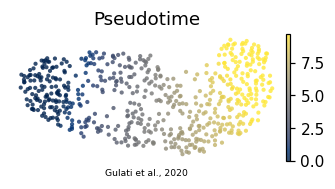

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Gulati et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')